# Run SpatialFlow On RRmap `.h5ad`

This notebook converts one RRmap-style `.h5ad` into SpatialFlow input folders, writes a run config with matching coordinate resolution, and launches training.


In [1]:
from pathlib import Path
import sys
import subprocess

import yaml
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "spatialflow").exists() and (ROOT.parent / "spatialflow").exists():
    ROOT = ROOT.parent

H5AD_PATH = Path("/Volumes/processing2/RRmap/data/RRmap_metadata_fixed_update.h5ad")
CONVERTED_DIR = ROOT / "data" / "rrmap_converted"
OUTPUT_DIR = ROOT / "outputs" / "rrmap_run"
EVAL_OUTPUT_DIR = ROOT / "outputs" / "rrmap_eval"
BASE_CONFIG = ROOT / "configs" / "default_config.yaml"
RUN_CONFIG = ROOT / "configs" / "rrmap_user_config.yaml"

# Tuning knobs
N_GENES = 500
MAX_CELLS_PER_SECTION = 3000   # set 0 for full dataset
COORD_SCALE_UM = 8.0
MIRROR_BILATERAL = False       # True doubles cells per section
CHECKPOINT_EVERY = 1
N_EPOCHS = 20                  # 2 for smoke test, >=20 for signal
RUN_VALIDATE = True
RUN_ATTRIBUTE = False
RUN_EVALUATE = True
EVAL_LEIDEN_RESOLUTION = 0.5

try:
    import torch
    if torch.cuda.is_available():
        DEVICE = "cuda"
    elif torch.backends.mps.is_available():
        DEVICE = "mps"
    else:
        DEVICE = "cpu"
except Exception:
    DEVICE = "cpu"

print(f"ROOT: {ROOT}")
print(f"DEVICE: {DEVICE}")
print(f"H5AD exists: {H5AD_PATH.exists()}")
print(f"Converted data dir: {CONVERTED_DIR}")
print(f"Training output dir: {OUTPUT_DIR}")
print(f"Eval output dir: {EVAL_OUTPUT_DIR}")


ROOT: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow
DEVICE: mps
H5AD exists: True
Converted data dir: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted
Training output dir: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/outputs/rrmap_run
Eval output dir: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/outputs/rrmap_eval


In [2]:
required_files = [
    ROOT / "scripts" / "convert_rrmap_h5ad.py",
    ROOT / "scripts" / "train.py",
    ROOT / "scripts" / "evaluate.py",
    BASE_CONFIG,
]
for p in required_files:
    if not p.exists():
        raise FileNotFoundError(f"Missing required file: {p}")

if not H5AD_PATH.exists():
    raise FileNotFoundError(f"Input file not found: {H5AD_PATH}")

CONVERTED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Pre-checks passed.")


Pre-checks passed.


## 1) Convert `.h5ad` to SpatialFlow folder layout

In [3]:
convert_cmd = [
    sys.executable,
    str(ROOT / "scripts" / "convert_rrmap_h5ad.py"),
    "--h5ad", str(H5AD_PATH),
    "--output_dir", str(CONVERTED_DIR),
    "--n_genes", str(N_GENES),
    "--max_cells_per_section", str(MAX_CELLS_PER_SECTION),
    "--coord_scale_um", str(COORD_SCALE_UM),
]

print("Running:")
print(" ".join(convert_cmd))
subprocess.run(convert_cmd, check=True, cwd=str(ROOT))
print("Conversion finished.")


Running:
/Users/chrislangseth/miniforge3/envs/cellcharter/bin/python /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/scripts/convert_rrmap_h5ad.py --h5ad /Volumes/processing2/RRmap/data/RRmap_metadata_fixed_update.h5ad --output_dir /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted --n_genes 500 --max_cells_per_section 3000 --coord_scale_um 8.0


2026-02-26 21:24:39,960 [INFO] convert_rrmap_h5ad - Input shape: 877141 cells x 5101 genes
2026-02-26 21:24:41,827 [INFO] convert_rrmap_h5ad - Selected 100 genes
2026-02-26 21:24:41,896 [INFO] convert_rrmap_h5ad - Found 36 section groups
2026-02-26 21:24:43,256 [INFO] convert_rrmap_h5ad - Wrote /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted/MOG/chronic_peak/output-XETG00045__0020770__G3_L1__20250110__134105 (MOG/chronic_peak, 3000 cells)
2026-02-26 21:24:44,305 [INFO] convert_rrmap_h5ad - Wrote /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted/MOG/chronic_peak/output-XETG00045__0020770__G3_L2__20250110__134105 (MOG/chronic_peak, 3000 cells)
2026-02-26 21:24:45,339 [INFO] convert_rrmap_h5ad - Wrote /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted/MOG/chronic_peak/output-XETG00045__0020770__G3_L3__20250110__134105 (MOG/chronic_peak, 3000 cells)
2026-02-26 21:24:46,1

Conversion finished.


2026-02-26 21:25:10,001 [INFO] convert_rrmap_h5ad - Wrote /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted/PLP/baseline/output-XETG00047__0054727__S3-T3__20250605__134857 (PLP/baseline, 3000 cells)
2026-02-26 21:25:10,011 [INFO] convert_rrmap_h5ad - Wrote manifest: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted/conversion_manifest.csv
2026-02-26 21:25:10,011 [INFO] convert_rrmap_h5ad - Done. Set config resolution_um to 8.000 to match coordinate downscaling.


In [4]:
manifest_path = CONVERTED_DIR / "conversion_manifest.csv"
if not manifest_path.exists():
    raise FileNotFoundError(f"Missing conversion manifest: {manifest_path}")

manifest = pd.read_csv(manifest_path)
display(manifest.head(12))
print(f"Sections: {len(manifest)}")
print("Cells per model:")
display(manifest.groupby("model_type")["n_cells"].sum().to_frame())


,section,model_type,timepoint,n_cells,n_genes
0,output-XETG00045__0020782__G6_L3__20250110__13...,MOG,baseline,3000,100
1,output-XETG00045__0020770__G4_L1__20250110__13...,MOG,chronic_long,3000,100
2,output-XETG00045__0020770__G4_L2__20250110__13...,MOG,chronic_long,3000,100
3,output-XETG00045__0020770__G4_L3__20250110__13...,MOG,chronic_long,3000,100
4,output-XETG00045__0020782__G6_L1__20250110__13...,MOG,chronic_long,3000,100
5,output-XETG00045__0020782__G6_L2__20250110__13...,MOG,chronic_long,3000,100
6,output-XETG00045__0020770__G3_L1__20250110__13...,MOG,chronic_peak,3000,100
7,output-XETG00045__0020770__G3_L2__20250110__13...,MOG,chronic_peak,3000,100
8,output-XETG00045__0020770__G3_L3__20250110__13...,MOG,chronic_peak,3000,100
9,output-XETG00045__0020782__G5_L1__20250110__13...,MOG,chronic_peak,3000,100


Sections: 36
Cells per model:


,n_cells
model_type,
MOG,36000
PLP,72000


## 2) Write run config (match `resolution_um` to conversion scale)

In [5]:
with open(BASE_CONFIG) as f:
    cfg = yaml.safe_load(f)

cfg["resolution_um"] = float(COORD_SCALE_UM)
cfg["mirror_bilateral"] = bool(MIRROR_BILATERAL)
cfg["checkpoint_every"] = int(CHECKPOINT_EVERY)

with open(RUN_CONFIG, "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print(f"Wrote config: {RUN_CONFIG}")
print(f"resolution_um = {cfg['resolution_um']}")
print(f"mirror_bilateral = {cfg['mirror_bilateral']}")
print(f"checkpoint_every = {cfg['checkpoint_every']}")


Wrote config: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/configs/rrmap_user_config.yaml
resolution_um = 8.0
mirror_bilateral = False
checkpoint_every = 1


## 3) Train SpatialFlow

In [6]:
train_cmd = [
    sys.executable,
    str(ROOT / "scripts" / "train.py"),
    "--data_dir", str(CONVERTED_DIR),
    "--config", str(RUN_CONFIG),
    "--output_dir", str(OUTPUT_DIR),
    "--device", DEVICE,
    "--n_epochs", str(N_EPOCHS),
]

if RUN_VALIDATE:
    train_cmd.append("--validate")
if RUN_ATTRIBUTE:
    train_cmd.append("--attribute")

print("Running:")
print(" ".join(train_cmd))

try:
    subprocess.run(train_cmd, check=True, cwd=str(ROOT))
except subprocess.CalledProcessError:
    if DEVICE == "mps":
        print("MPS run failed. Retrying on CPU ...")
        cpu_cmd = train_cmd.copy()
        cpu_cmd[cpu_cmd.index("--device") + 1] = "cpu"
        print(" ".join(cpu_cmd))
        subprocess.run(cpu_cmd, check=True, cwd=str(ROOT))
    else:
        raise

print("Training run complete.")


Running:
/Users/chrislangseth/miniforge3/envs/cellcharter/bin/python /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/scripts/train.py --data_dir /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted --config /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/configs/rrmap_user_config.yaml --output_dir /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/outputs/rrmap_run --device mps --n_epochs 20 --validate


2026-02-26 21:25:15,375 [INFO] train — ============================================================
2026-02-26 21:25:15,375 [INFO] train — EAE-SpatialFlow v4 — Training
2026-02-26 21:25:15,376 [INFO] train — Device: mps | Config: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/configs/rrmap_user_config.yaml
2026-02-26 21:25:15,376 [INFO] train — ============================================================
2026-02-26 21:25:15,521 [INFO] train — Loaded section: MOG_baseline_output-XETG00045__0020782__G6_L3__20250110__134105 (3000 cells)
2026-02-26 21:25:15,529 [INFO] train — Loaded section: MOG_chronic_peak_output-XETG00045__0020770__G3_L1__20250110__134105 (3000 cells)
2026-02-26 21:25:15,538 [INFO] train — Loaded section: MOG_chronic_peak_output-XETG00045__0020770__G3_L2__20250110__134105 (3000 cells)
2026-02-26 21:25:15,546 [INFO] train — Loaded section: MOG_chronic_peak_output-XETG00045__0020770__G3_L3__20250110__134105 (3000 cells)
2026-02-26 21:25:15,554 [INFO]

Training run complete.


In [7]:
files = sorted([p for p in OUTPUT_DIR.rglob("*") if p.is_file()])
print(f"Output files: {len(files)}")
for p in files[:50]:
    print(p.relative_to(ROOT))
if len(files) > 50:
    print("... (truncated)")


Output files: 23
outputs/rrmap_run/checkpoints/spatialflow_epoch0001.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0002.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0003.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0004.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0005.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0006.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0007.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0008.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0009.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0010.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0011.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0012.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0013.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0014.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0015.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0016.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0017.pt
outputs/rrmap_run/checkpoints/spatialflow_epoch0

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

div = pd.read_csv(OUTPUT_DIR / "divergence_scores.csv")
vel = pd.read_parquet(OUTPUT_DIR / "niche_velocity.parquet")

print("Cells:", len(div), "Sections:", div["section_id"].nunique())
print("Velocity nonzero frac:", float((vel["velocity_magnitude"] > 0).mean()))
print("Momentum nonzero frac:", float((vel["inf_momentum"] != 0).mean()))
print("Relapse nursery frac:", float(div["relapse_nursery"].mean()))

print("\nDivergence by model")
display(div.groupby("model_type")["divergence"].agg(["mean", "std", "median"]))

print("\nBifurcation fraction by model/timepoint")
display(
    div.groupby(["model_type", "timepoint"])["bifurcation"]
      .mean()
      .reset_index()
      .sort_values(["model_type", "timepoint"])
)

sec = (
    div.groupby(["section_id", "model_type", "timepoint"])
      .agg(
          mean_div=("divergence", "mean"),
          bif_frac=("bifurcation", "mean"),
          nursery_frac=("relapse_nursery", "mean"),
          n=("cell_idx", "count"),
      )
      .reset_index()
)

print("\nTop sections by mean divergence")
display(sec.sort_values("mean_div", ascending=False).head(15))
print("\nTop sections by bifurcation fraction")
display(sec.sort_values("bif_frac", ascending=False).head(15))


Cells: 108000 Sections: 36
Velocity nonzero frac: 0.0
Momentum nonzero frac: 0.0
Relapse nursery frac: 0.007361111111111111

Divergence by model


,mean,std,median
model_type,,,
MOG,4.314937e-08,0.999847,-0.064832
PLP,3.186982e-07,0.999840,-0.058919



Bifurcation fraction by model/timepoint


,model_type,timepoint,bifurcation
0,MOG,baseline,0.012333
1,MOG,chronic_long,0.013333
2,MOG,chronic_peak,0.012111
3,PLP,baseline,0.080333
4,PLP,monophasic,0.031000
5,PLP,onset_I,0.006333
6,PLP,onset_II,0.024000
7,PLP,peak_I,0.057200
8,PLP,peak_III,0.059133
9,PLP,remission_I,0.063417



Top sections by mean divergence


,section_id,model_type,timepoint,mean_div,bif_frac,nursery_frac,n
31,PLP_peak_I_output-XETG00047__0054727__S3-B2__2...,PLP,peak_I,7.180369e-06,0.223667,0.000000,3000
23,PLP_peak_III_output-XETG00045__0054856__S2-T3_...,PLP,peak_III,5.751830e-06,0.253333,0.000000,3000
16,PLP_monophasic_output-XETG00045__0054856__S2-B...,PLP,monophasic,2.860036e-06,0.082000,0.000000,3000
12,PLP_baseline_output-XETG00045__0054415__S1-T1_...,PLP,baseline,5.185399e-07,0.288667,0.000000,3000
21,PLP_onset_I_output-XETG00047__0054723__S4-T1__...,PLP,onset_I,4.649892e-07,0.006333,0.004000,3000
2,MOG_chronic_long_output-XETG00045__0020770__G4...,MOG,chronic_long,4.477916e-07,0.003333,0.003333,3000
15,PLP_baseline_output-XETG00047__0054727__S3-T3_...,PLP,baseline,3.368945e-07,0.010000,0.007000,3000
34,PLP_remission_I_output-XETG00047__0054723__S4-...,PLP,remission_I,3.357901e-07,0.004000,0.002333,3000
26,PLP_peak_III_output-XETG00047__0054727__S3-B3_...,PLP,peak_III,2.859412e-07,0.013333,0.008333,3000
25,PLP_peak_III_output-XETG00047__0054723__S4-B3_...,PLP,peak_III,2.231561e-07,0.012333,0.009667,3000



Top sections by bifurcation fraction


,section_id,model_type,timepoint,mean_div,bif_frac,nursery_frac,n
12,PLP_baseline_output-XETG00045__0054415__S1-T1_...,PLP,baseline,5.185399e-07,0.288667,0.000000,3000
23,PLP_peak_III_output-XETG00045__0054856__S2-T3_...,PLP,peak_III,5.751830e-06,0.253333,0.000000,3000
32,PLP_remission_I_output-XETG00045__0054415__S1-...,PLP,remission_I,-9.692754e-06,0.228333,0.000000,3000
31,PLP_peak_I_output-XETG00047__0054727__S3-B2__2...,PLP,peak_I,7.180369e-06,0.223667,0.000000,3000
16,PLP_monophasic_output-XETG00045__0054856__S2-B...,PLP,monophasic,2.860036e-06,0.082000,0.000000,3000
20,PLP_onset_II_output-XETG00045__0054856__S2-B1_...,PLP,onset_II,3.173544e-08,0.024000,0.014667,3000
28,PLP_peak_I_output-XETG00045__0054415__S1-T2__2...,PLP,peak_I,-6.701797e-09,0.023333,0.014667,3000
18,PLP_monophasic_output-XETG00047__0054723__S4-B...,PLP,monophasic,2.042521e-07,0.021333,0.017333,3000
4,MOG_chronic_long_output-XETG00045__0020782__G6...,MOG,chronic_long,3.395913e-09,0.020333,0.014000,3000
35,PLP_remission_I_output-XETG00047__0054723__S4-...,PLP,remission_I,-1.280239e-07,0.017667,0.015667,3000


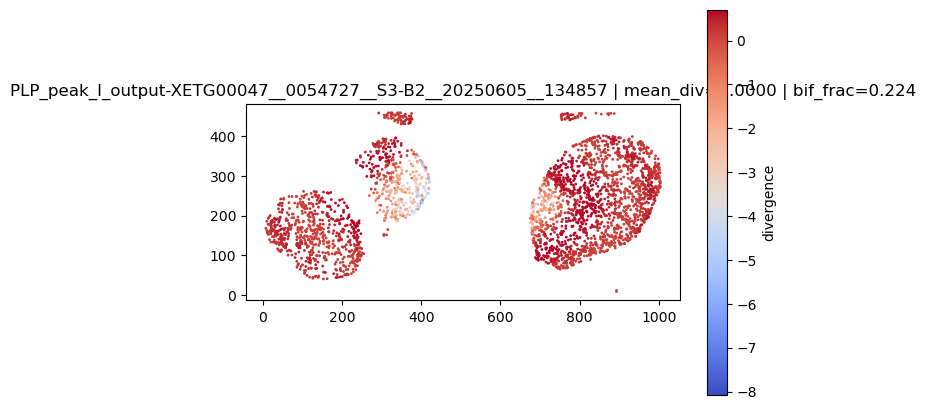

In [9]:
# Pick which ranked section to plot
PLOT_RANK = 0

if len(sec) == 0:
    raise RuntimeError("No section summaries found in divergence_scores.csv")

row = sec.sort_values("mean_div", ascending=False).iloc[PLOT_RANK]
sid = row["section_id"]
m = row["model_type"]
tp = row["timepoint"]
prefix = f"{m}_{tp}_"
sec_name = sid[len(prefix):]

cells = pd.read_parquet(CONVERTED_DIR / m / tp / sec_name / "cells.parquet")
dsec = div[div["section_id"] == sid].sort_values("cell_idx")
plot_df = cells.join(dsec.set_index("cell_idx")[["divergence", "bifurcation"]], how="left")

plt.figure(figsize=(7, 5))
plt.scatter(plot_df["x"], plot_df["y"], c=plot_df["divergence"], s=1, cmap="coolwarm")
plt.gca().set_aspect("equal")
plt.title(f"{sid} | mean_div={row['mean_div']:.4f} | bif_frac={row['bif_frac']:.3f}")
plt.colorbar(label="divergence")
plt.show()


## 4) Optional: run `evaluate.py` to generate figures and niche annotations

This requires at least one checkpoint in `OUTPUT_DIR/checkpoints/`.


In [11]:
from pathlib import Path

if not RUN_EVALUATE:
    print("RUN_EVALUATE=False, skipping evaluation.")
else:
    ckpt_dir = OUTPUT_DIR / "checkpoints"
    ckpts = sorted(ckpt_dir.glob("spatialflow_epoch*.pt"))
    if not ckpts:
        print(f"No checkpoints found in {ckpt_dir}. Set CHECKPOINT_EVERY=1 and rerun training.")
    else:
        latest_ckpt = ckpts[-1]
        eval_cmd = [
            sys.executable,
            str(ROOT / "scripts" / "evaluate.py"),
            "--checkpoint", str(latest_ckpt),
            "--data_dir", str(CONVERTED_DIR),
            "--config", str(RUN_CONFIG),
            "--output_dir", str(EVAL_OUTPUT_DIR),
            "--device", DEVICE,
            "--leiden_resolution", str(EVAL_LEIDEN_RESOLUTION),
        ]
        print("Running:")
        print(" ".join(eval_cmd))
        try:
            subprocess.run(eval_cmd, check=True, cwd=str(ROOT))
        except subprocess.CalledProcessError:
            if DEVICE == "mps":
                print("MPS evaluation failed. Retrying on CPU ...")
                cpu_cmd = eval_cmd.copy()
                cpu_cmd[cpu_cmd.index("--device") + 1] = "cpu"
                print(" ".join(cpu_cmd))
                subprocess.run(cpu_cmd, check=True, cwd=str(ROOT))
            else:
                raise
        print("Evaluation complete.")


Running:
/Users/chrislangseth/miniforge3/envs/cellcharter/bin/python /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/scripts/evaluate.py --checkpoint /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/outputs/rrmap_run/checkpoints/spatialflow_epoch0020.pt --data_dir /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/data/rrmap_converted --config /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/configs/rrmap_user_config.yaml --output_dir /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/outputs/rrmap_eval --device mps --leiden_resolution 0.5


2026-02-26 21:53:41,417 [INFO] evaluate — Loading checkpoint: /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/outputs/rrmap_run/checkpoints/spatialflow_epoch0020.pt
2026-02-26 21:53:41,418 [INFO] spatialflow.graph_builder — LRDatabase loaded: 15 pairs (source=fallback)
2026-02-26 21:53:41,495 [INFO] spatialflow.pipeline — Model initialised: 662,327 parameters.
2026-02-26 21:53:41,496 [INFO] spatialflow.pipeline — Checkpoint loaded from /Users/chrislangseth/work/karolinska_institutet/projects/SpatialFlow/outputs/rrmap_run/checkpoints/spatialflow_epoch0020.pt (epoch 20)
2026-02-26 21:53:41,496 [INFO] evaluate — Loading sections …
2026-02-26 21:53:41,619 [INFO] train — Loaded section: MOG_baseline_output-XETG00045__0020782__G6_L3__20250110__134105 (3000 cells)
2026-02-26 21:53:41,628 [INFO] train — Loaded section: MOG_chronic_peak_output-XETG00045__0020770__G3_L1__20250110__134105 (3000 cells)
2026-02-26 21:53:41,636 [INFO] train — Loaded section: MOG_chronic_peak_out

Evaluation complete.


In [12]:
eval_files = sorted([p for p in EVAL_OUTPUT_DIR.rglob("*") if p.is_file()])
print(f"Eval files: {len(eval_files)}")
for p in eval_files[:80]:
    print(p.relative_to(ROOT))
if len(eval_files) > 80:
    print("... (truncated)")


Eval files: 9
outputs/rrmap_eval/figures/divergence_heatmap_all.pdf
outputs/rrmap_eval/figures/divergence_trajectory_mog.pdf
outputs/rrmap_eval/figures/divergence_trajectory_plp.pdf
outputs/rrmap_eval/figures/niche_cluster_spatial.pdf
outputs/rrmap_eval/figures/relapse_probability_plp.pdf
outputs/rrmap_eval/figures/trajectory_umap_clusters.pdf
outputs/rrmap_eval/figures/trajectory_umap_model.pdf
outputs/rrmap_eval/figures/trajectory_umap_velocity.pdf
outputs/rrmap_eval/niche_annotations.csv
